# Разведочный анализ House Prices

**Дисциплина:** «Системы искусственного интеллекта» — курсовой проект.

**Цель:** изучить структуру и качество набора данных Ames Housing, выполнить EDA и сформулировать задачи регрессии, классификации и кластеризации.

Источник: [House Prices — Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data).

**Примечание:** данные используются локально после принятия условий Kaggle. Этот Notebook не выводит исходные строки набора и не содержит сам `train.csv`. Для его выполнения необходимо запустить Jupyter из корня репозитория.


## Загрузка и первичное исследование

Загружаем оригинальный `data/raw/train.csv` без его изменения. Отдельно проверяем количество объектов, типы данных, дубликаты и пропуски. Результаты строятся функциями пакета `house_prices_ai`, чтобы избежать дублирования кода.


In [1]:
from IPython.display import display, Image, Markdown
from pathlib import Path
import sys

# PyCharm может запускать Notebook как из корня репозитория, так и из notebooks/.
root = Path.cwd()
if not (root / "house_prices_ai").is_dir():
    root = root.parent
if not (root / "house_prices_ai").is_dir():
    raise FileNotFoundError("Не найдён корень проекта house-prices-ai")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from house_prices_ai.eda import run_eda, HIGH_PRICE_THRESHOLD
from house_prices_ai.config import RAW_TRAIN_FILE, OUTPUT_DIR

result = run_eda(RAW_TRAIN_FILE, OUTPUT_DIR / "eda")
print(f"Наблюдений: {result.observations}; столбцов: {result.columns}")
print(f"Числовых: {result.numeric_columns}; текстовых: {result.categorical_columns}")
print(f"Пропусков: {result.missing_total}")
print(f"Полных дубликатов: {result.duplicate_rows}")
print(f"Дубликатов без Id: {result.duplicate_feature_rows}")
print(f"Повторов Id: {result.duplicate_ids}")
print(f"Локальный отчёт: {result.report_path}")

Наблюдений: 1460; столбцов: 81
Числовых: 38; текстовых: 43
Пропусков: 6965
Полных дубликатов: 0
Дубликатов без Id: 0
Повторов Id: 0
Локальный отчёт: F:\JetBrainsProjects\PycharmProjects\house-prices-ai\outputs\eda\lr01_eda_summary.md


In [2]:
display(result.dictionary)
print("Столбцы с пропусками:")
display(result.missing)

,Признак,Описание,Тип данных,Роль,Пропуски,"Пропуски, %",Уникальных значений
0,Id,Уникальный идентификатор объекта (не признак н...,int64,Идентификатор,0,0.00,1460
1,MSSubClass,Код типа жилого строения (категориальный код),int64,Категориальный код (хранится числом),0,0.00,15
2,MSZoning,Категория территориального зонирования,object,Категориальный признак,0,0.00,5
3,LotFrontage,"Протяжённость участка вдоль улицы, футы",float64,Числовой признак,259,17.74,110
4,LotArea,"Площадь земельного участка, кв. футы",int64,Числовой признак,0,0.00,1073
...,...,...,...,...,...,...,...
76,MoSold,Месяц продажи,int64,Числовой признак,0,0.00,12
77,YrSold,Год продажи,int64,Числовой признак,0,0.00,5
78,SaleType,Тип сделки продажи,object,Категориальный признак,0,0.00,9
79,SaleCondition,Условия продажи,object,Категориальный признак,0,0.00,6


Столбцы с пропусками:


,Признак,Пропуски,"Доля, %"
0,PoolQC,1453,99.52
1,MiscFeature,1406,96.30
2,Alley,1369,93.77
3,Fence,1179,80.75
4,FireplaceQu,690,47.26
5,LotFrontage,259,17.74
6,GarageCond,81,5.55
7,GarageFinish,81,5.55
8,GarageQual,81,5.55
9,GarageType,81,5.55


Пропущенные значения не всегда означают, что информация потеряна. Например, отсутствие записи в `PoolQC` (качество бассейна), `Alley` (тип подъездной аллеи) или `GarageType` (тип гаража) может указывать, что у дома нет соответствующего объекта. При предобработке данных необходимо учитывать смысл каждого признака, а не заменять все пропуски одним способом.

Таблица выше содержит русские названия и описания всех 81 столбца, их типы и доли пропусков. В пояснительной записке полный перечень удобно разместить в приложении.

## Описательная статистика

Для числовых характеристик рассматриваем минимум, максимум, квартили, медиану, среднее и стандартное отклонение. Для уровня «5» дополнительно анализируем асимметрию и эксцесс.


In [3]:
display(result.numeric_summary)
print("Наиболее асимметричные числовые признаки:")
display(result.skewness.abs().sort_values(ascending=False).head(12).to_frame("|Асимметрия|") )
print("Признаки с наибольшим по модулю эксцессом:")
display(result.kurtosis.abs().sort_values(ascending=False).head(12).to_frame("|Эксцесс|") )

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0


Наиболее асимметричные числовые признаки:


,|Асимметрия|
MiscVal,24.476794
PoolArea,14.828374
LotArea,12.207688
3SsnPorch,10.304342
LowQualFinSF,9.011341
KitchenAbvGr,4.488397
BsmtFinSF2,4.255261
ScreenPorch,4.122214
BsmtHalfBath,4.103403
EnclosedPorch,3.089872


Признаки с наибольшим по модулю эксцессом:


,|Эксцесс|
MiscVal,701.003342
PoolArea,223.268499
LotArea,203.243271
3SsnPorch,123.662379
LowQualFinSF,83.234817
KitchenAbvGr,21.532404
BsmtFinSF2,20.113338
ScreenPorch,18.439068
LotFrontage,17.452867
BsmtHalfBath,16.396642


## Визуализация распределений и анализ выбросов

Пояснения и комментарии поданы так, чтобы их можно было использовать в пояснительной записке.

### Гистограммы числовых характеристик

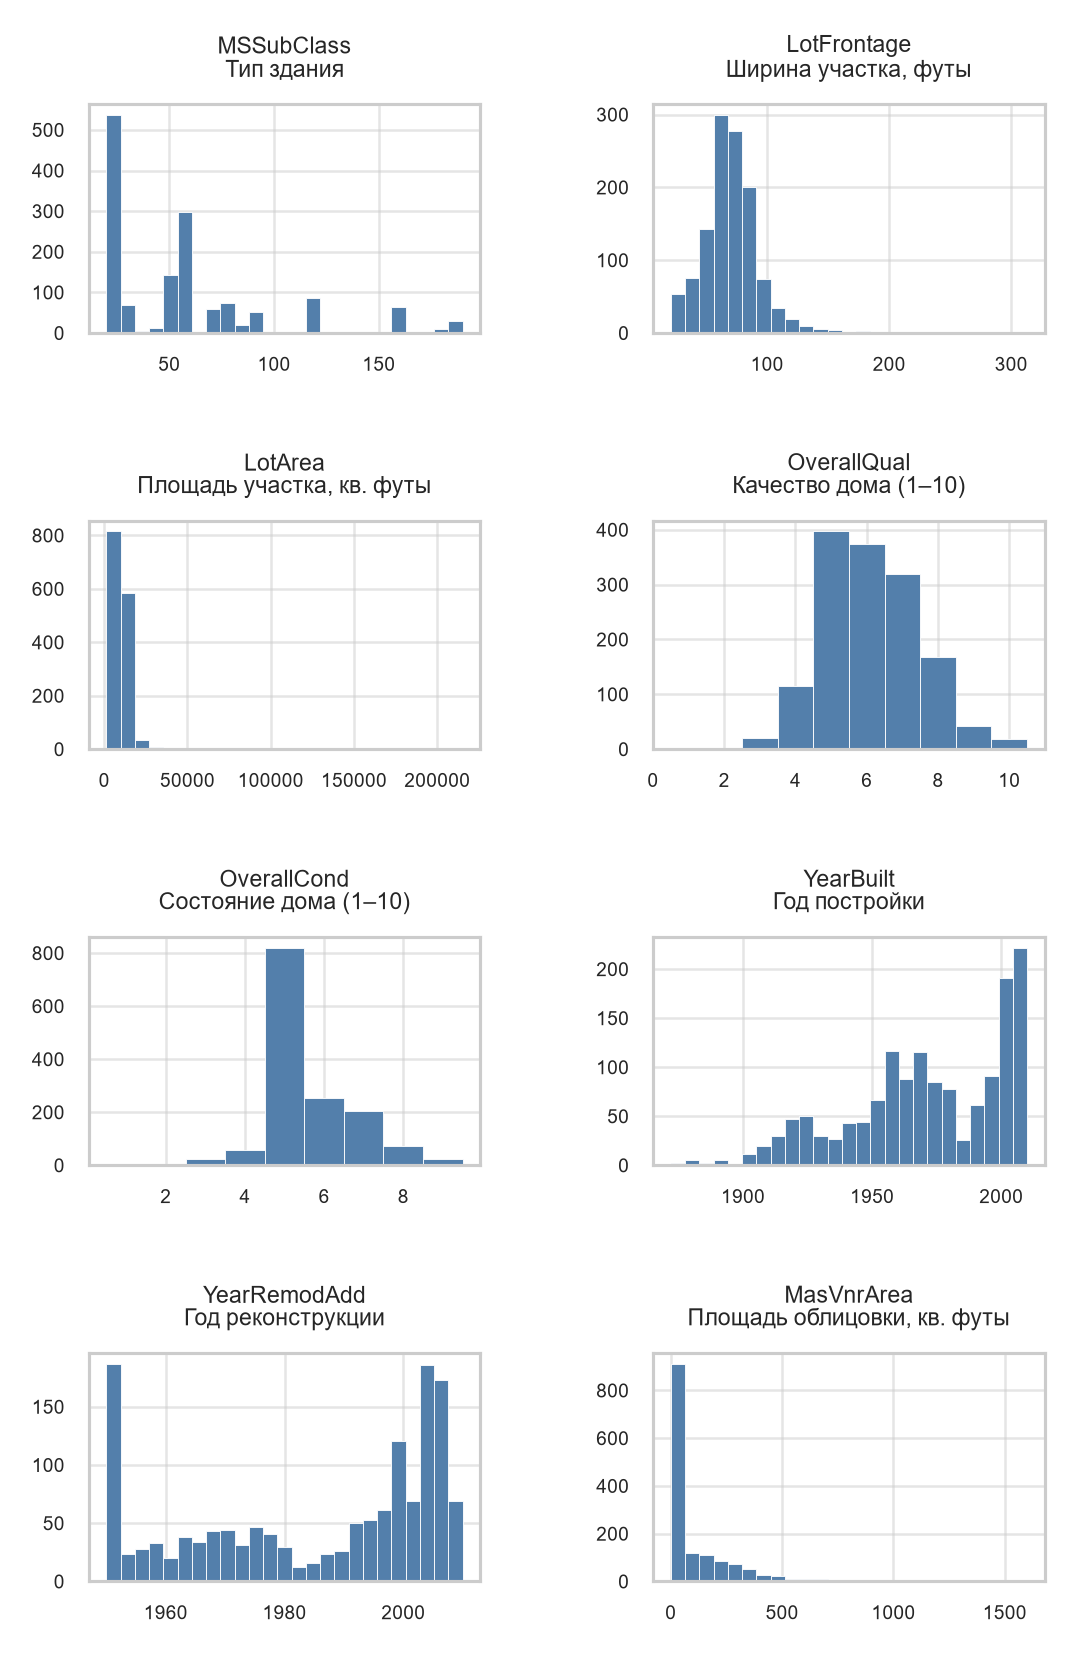

In [4]:
if "histograms_01" in result.plots:
    display(Image(filename=str(result.plots["histograms_01"])))

*Рисунок 1.1 — Тип застройки, площадь участка и качество дома.*

На этих гистограммах показаны тип строения, размеры участка, качество и возраст дома. Значения `MSSubClass` (тип здания) записаны числами, но на самом деле обозначают категории: разница между кодами не означает пропорциональную разницу между домами. `LotArea` (площадь участка) и `MasVnrArea` (площадь каменной облицовки) распределены неравномерно: большинство объектов имеет сравнительно небольшие значения, а крупные встречаются реже. `OverallQual` (общее качество дома) и `OverallCond` (общее состояние дома) оцениваются по дискретным шкалам. При дальнейшей обработке нужно учитывать, какие признаки являются кодами категорий, а какие — настоящими числовыми величинами.

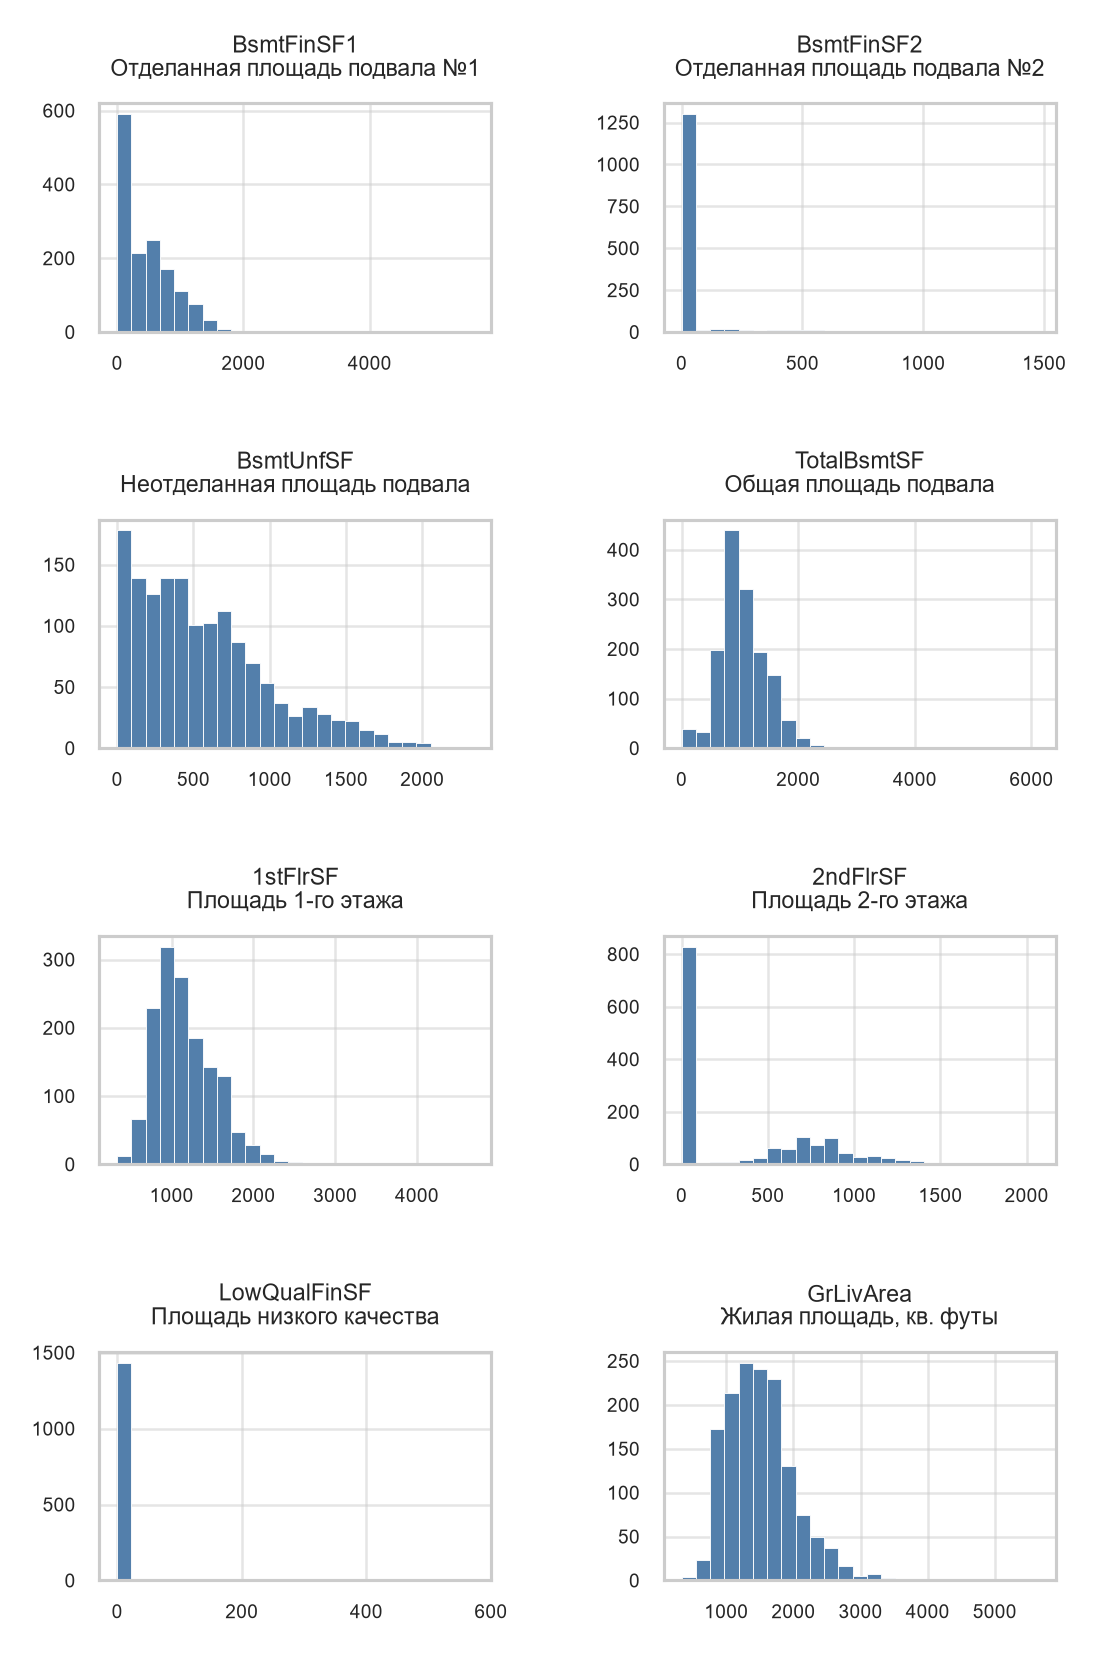

In [5]:
if "histograms_02" in result.plots:
    display(Image(filename=str(result.plots["histograms_02"])))

*Рисунок 1.2 — Площади подвала и жилых этажей.*

У многих домов отсутствуют отдельные виды помещений: поэтому нулевые значения `BsmtFinSF2` (отделанная площадь подвала второго типа), `2ndFlrSF` (площадь второго этажа) и `LowQualFinSF` (площадь помещений низкого качества) могут быть вполне корректными. Для `TotalBsmtSF` (общая площадь подвала) и `GrLivArea` (общая жилая площадь) заметен разброс: некоторые дома значительно просторнее большинства. При предобработке необходимо различать настоящие пропуски, отсутствие объекта (ноль) и необычно большие, но возможные значения.

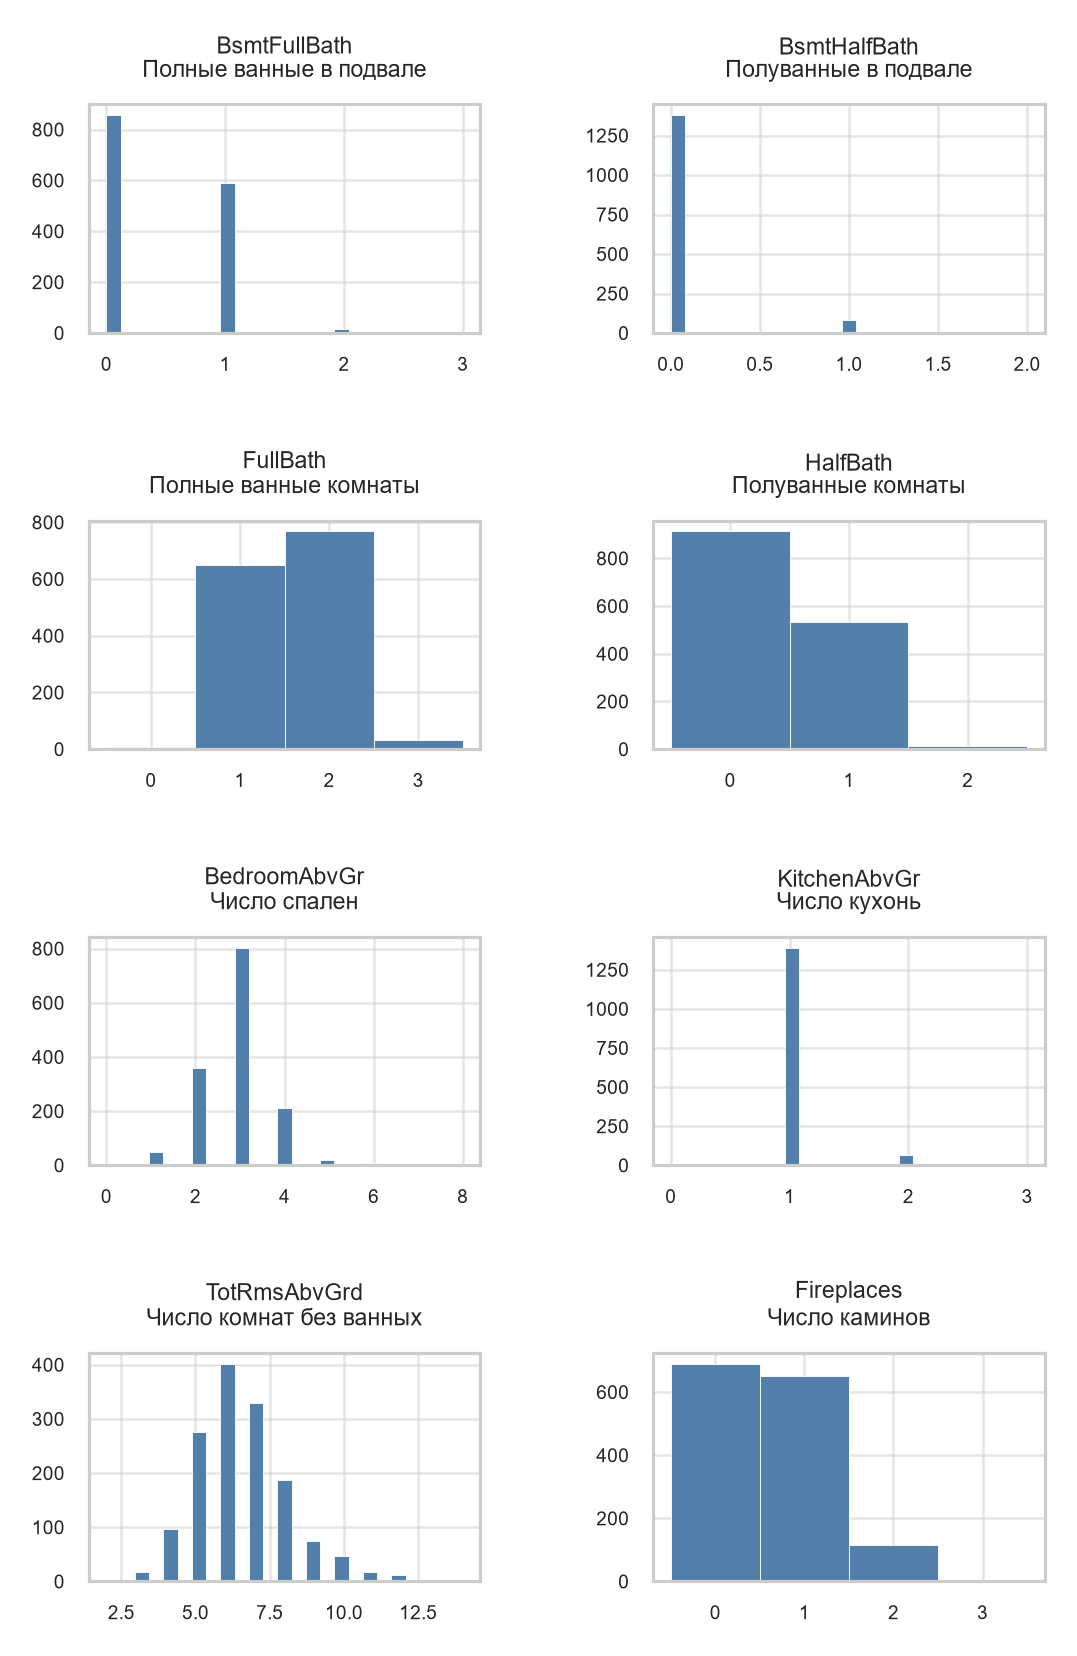

In [6]:
if "histograms_03" in result.plots:
    display(Image(filename=str(result.plots["histograms_03"])))

*Рисунок 1.3 — Ванные, спальни, комнаты и камины.*

Количество спален, ванных комнат и каминов не может принимать произвольные дробные значения, поэтому на графиках видны отдельные столбцы для целых чисел. Например, `BedroomAbvGr` (количество спален), `KitchenAbvGr` (количество кухонь) и `Fireplaces` (количество каминов) — счётные признаки. Нулевое значение часто просто означает отсутствие соответствующего помещения или оборудования. При подготовке моделей важно сохранить этот смысл и не требовать от таких распределений сходства с непрерывным нормальным распределением.

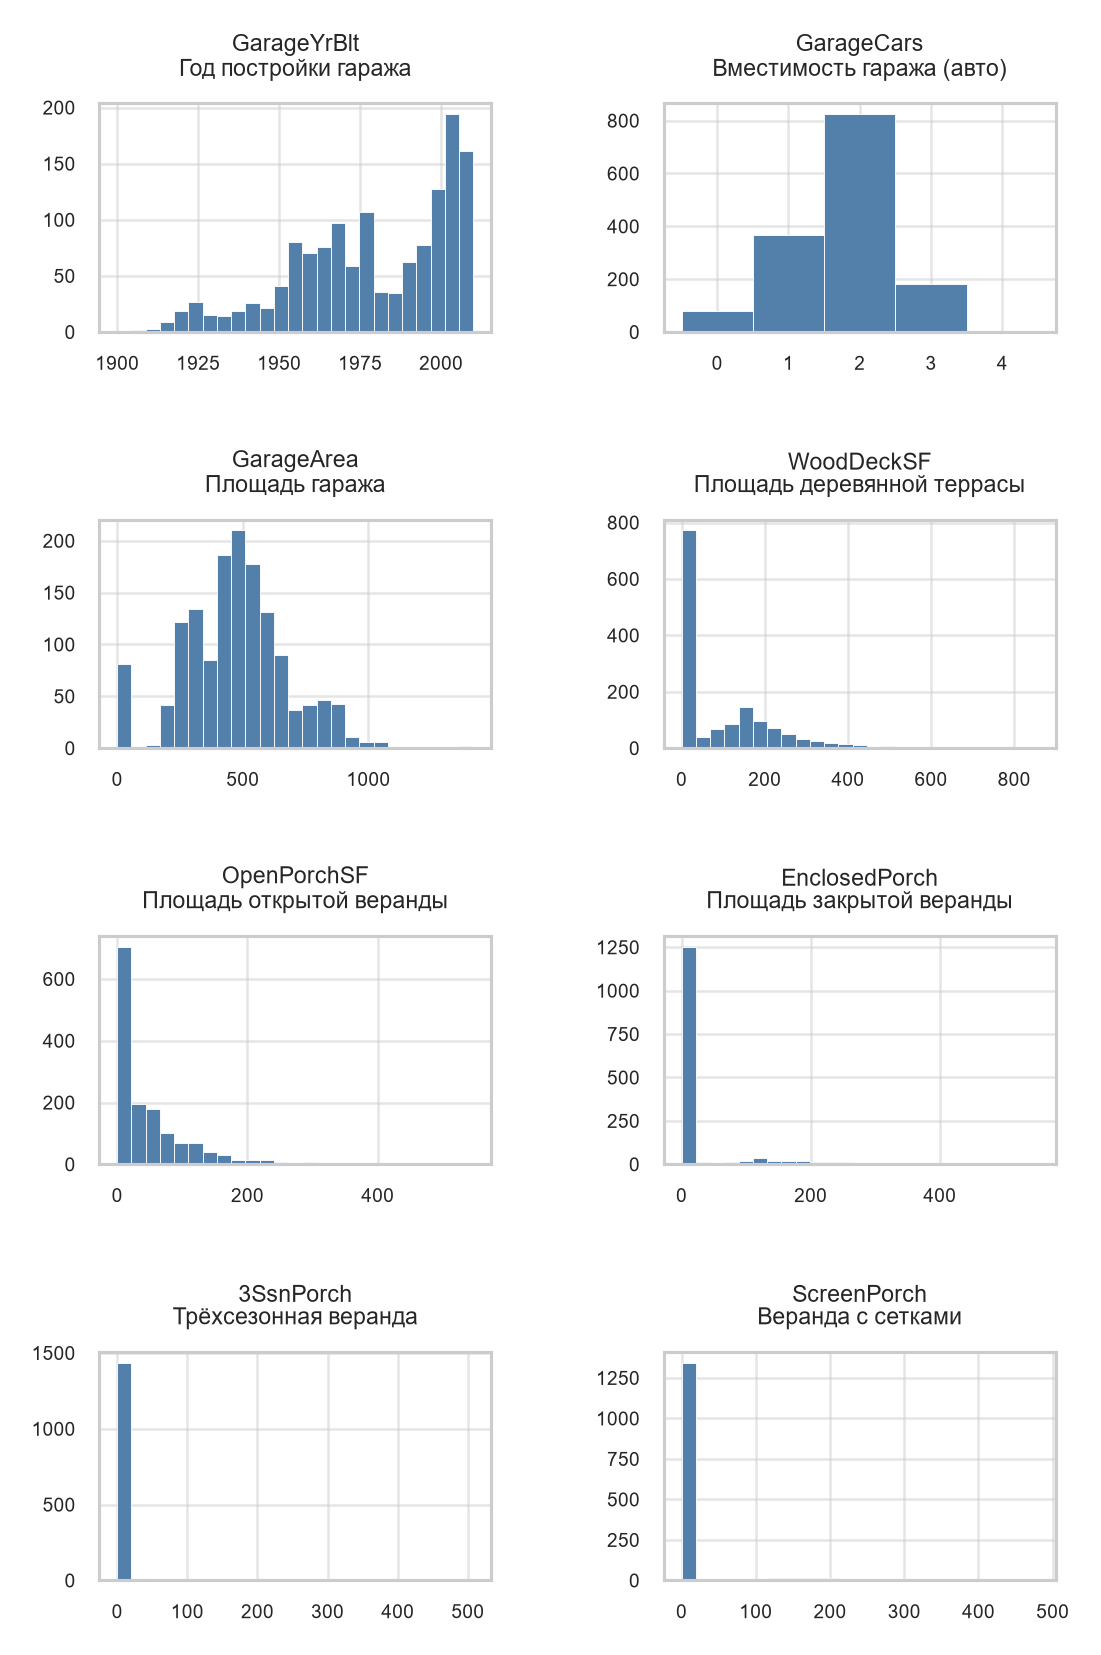

In [7]:
if "histograms_04" in result.plots:
    display(Image(filename=str(result.plots["histograms_04"])))

*Рисунок 1.4 — Гараж, террасы и крыльцо.*

`GarageCars` (вместимость гаража в автомобилях) и `GarageArea` (площадь гаража) описывают связанные свойства одного объекта: большой гараж обычно рассчитан на большее число автомобилей. У `WoodDeckSF` (площадь деревянной террасы) и `OpenPorchSF` (площадь открытого крыльца) часто встречается ноль, поскольку такие элементы есть не у каждого дома. В дальнейшем проверим взаимосвязь гаражных характеристик и будем отдельно учитывать признаки, отражающие отсутствие дополнительных построек.

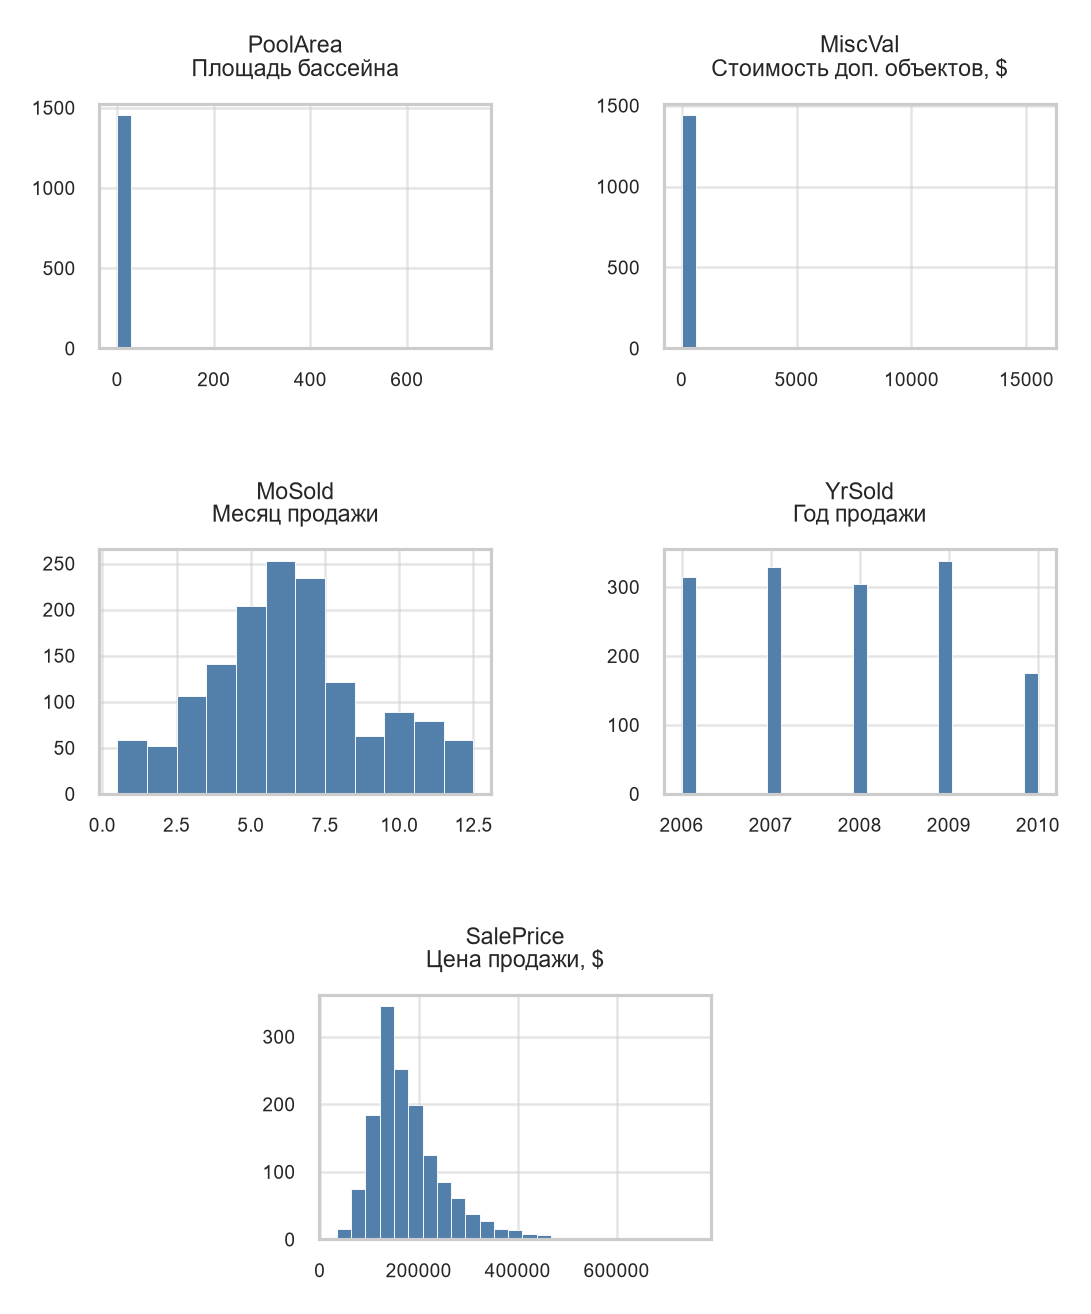

In [8]:
if "histograms_05" in result.plots:
    display(Image(filename=str(result.plots["histograms_05"])))

*Рисунок 1.5 — Редкие объекты, дата и цена продажи.*

`PoolArea` (площадь бассейна) и `MiscVal` (стоимость дополнительных объектов) у большинства домов равны нулю: бассейны и необычные дополнительные постройки встречаются редко. `MoSold` (месяц продажи) и `YrSold` (год продажи) характеризуют дату сделки. Распределение `SalePrice` (цена продажи) имеет длинный правый хвост: очень дорогих домов немного, но они повышают среднюю цену. При построении регрессионных моделей необходимо проверить, насколько такие объекты влияют на ошибки прогнозирования.

### Диаграммы размаха (boxplot)

Линия внутри прямоугольника — медиана, края — Q1/Q3, «усы» обычно ограничены 1,5 межквартильного размаха, отдельные чёрные точки показывают значения за пределами «усов». Это **потенциальные**, а не доказанные ошибки данных.

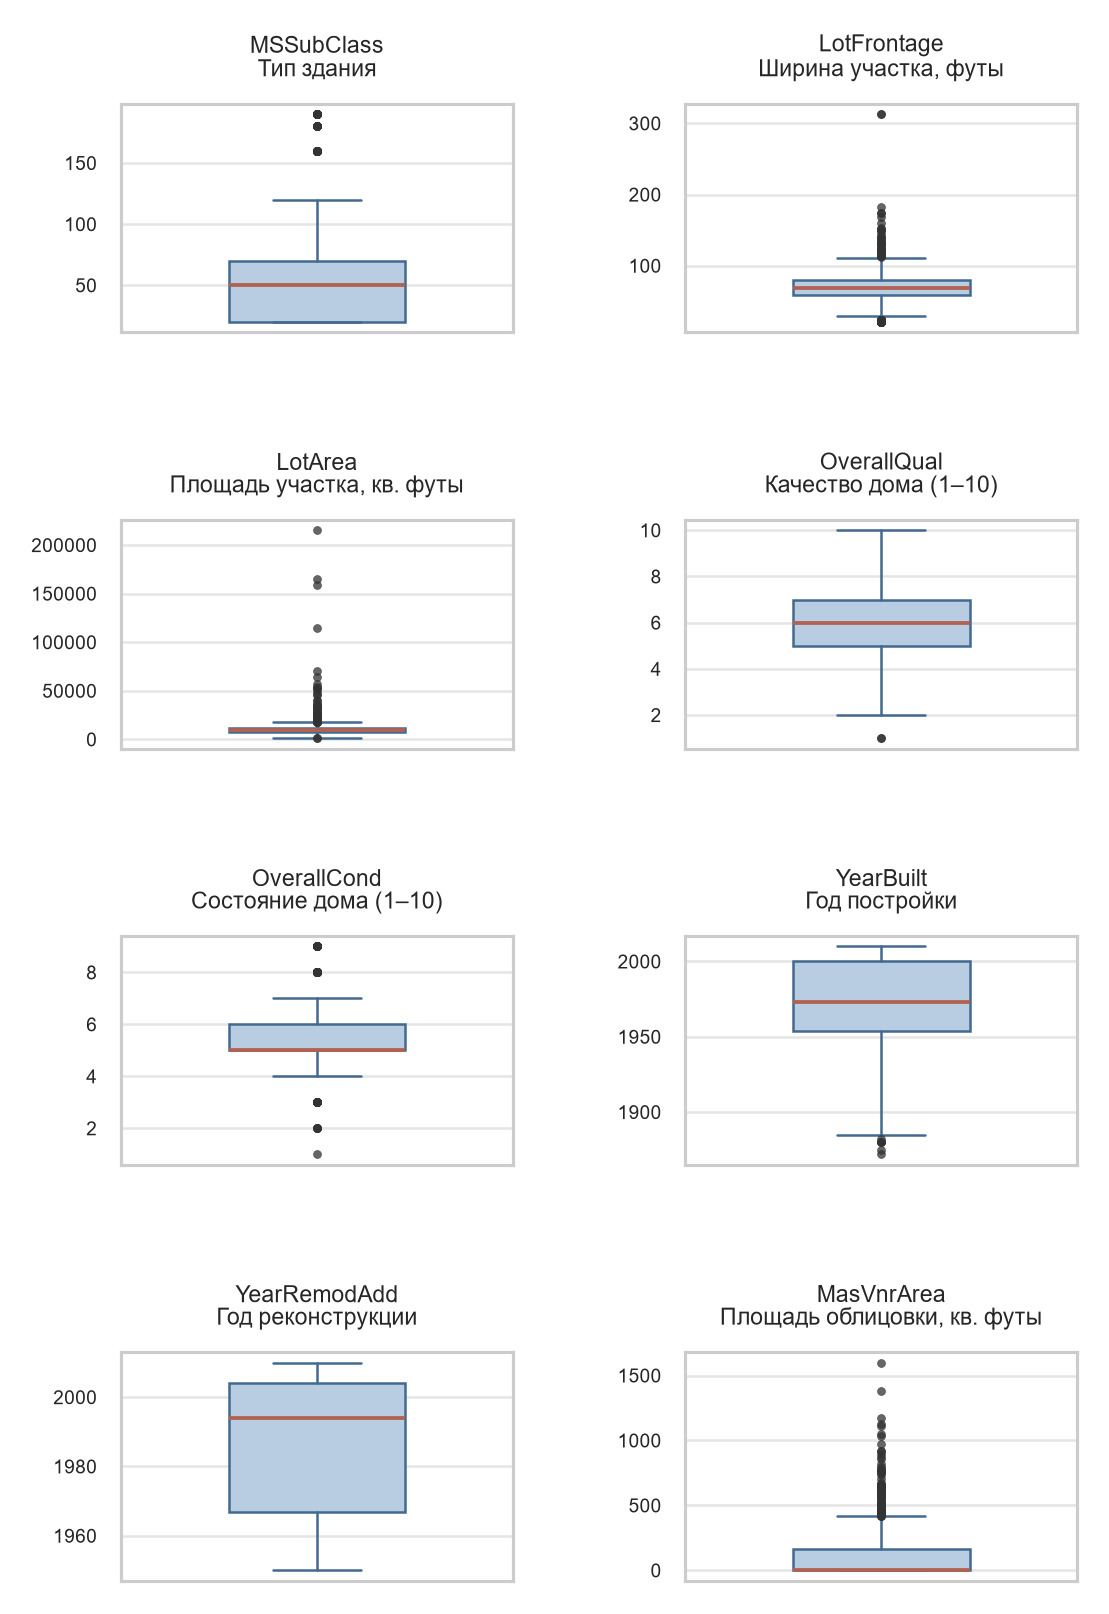

In [9]:
if "boxplots_01" in result.plots:
    display(Image(filename=str(result.plots["boxplots_01"])))

*Рисунок 1.6 — Выбросы в характеристиках участка и качества.*

На диаграммах размаха видны медиана, диапазон основной массы значений и отдельные точки за пределами «усов» (1,5 межквартильного размаха). Для `LotArea` (площадь участка) и `LotFrontage` (протяжённость границы участка вдоль улицы) такие точки могут соответствовать редким крупным участкам. `MSSubClass` (тип здания) и шкалы качества являются дискретными, поэтому значение за пределами «усов» не обязательно означает ошибку. На этом этапе ничего автоматически не удаляем: сначала нужно понять, насколько наблюдение правдоподобно.

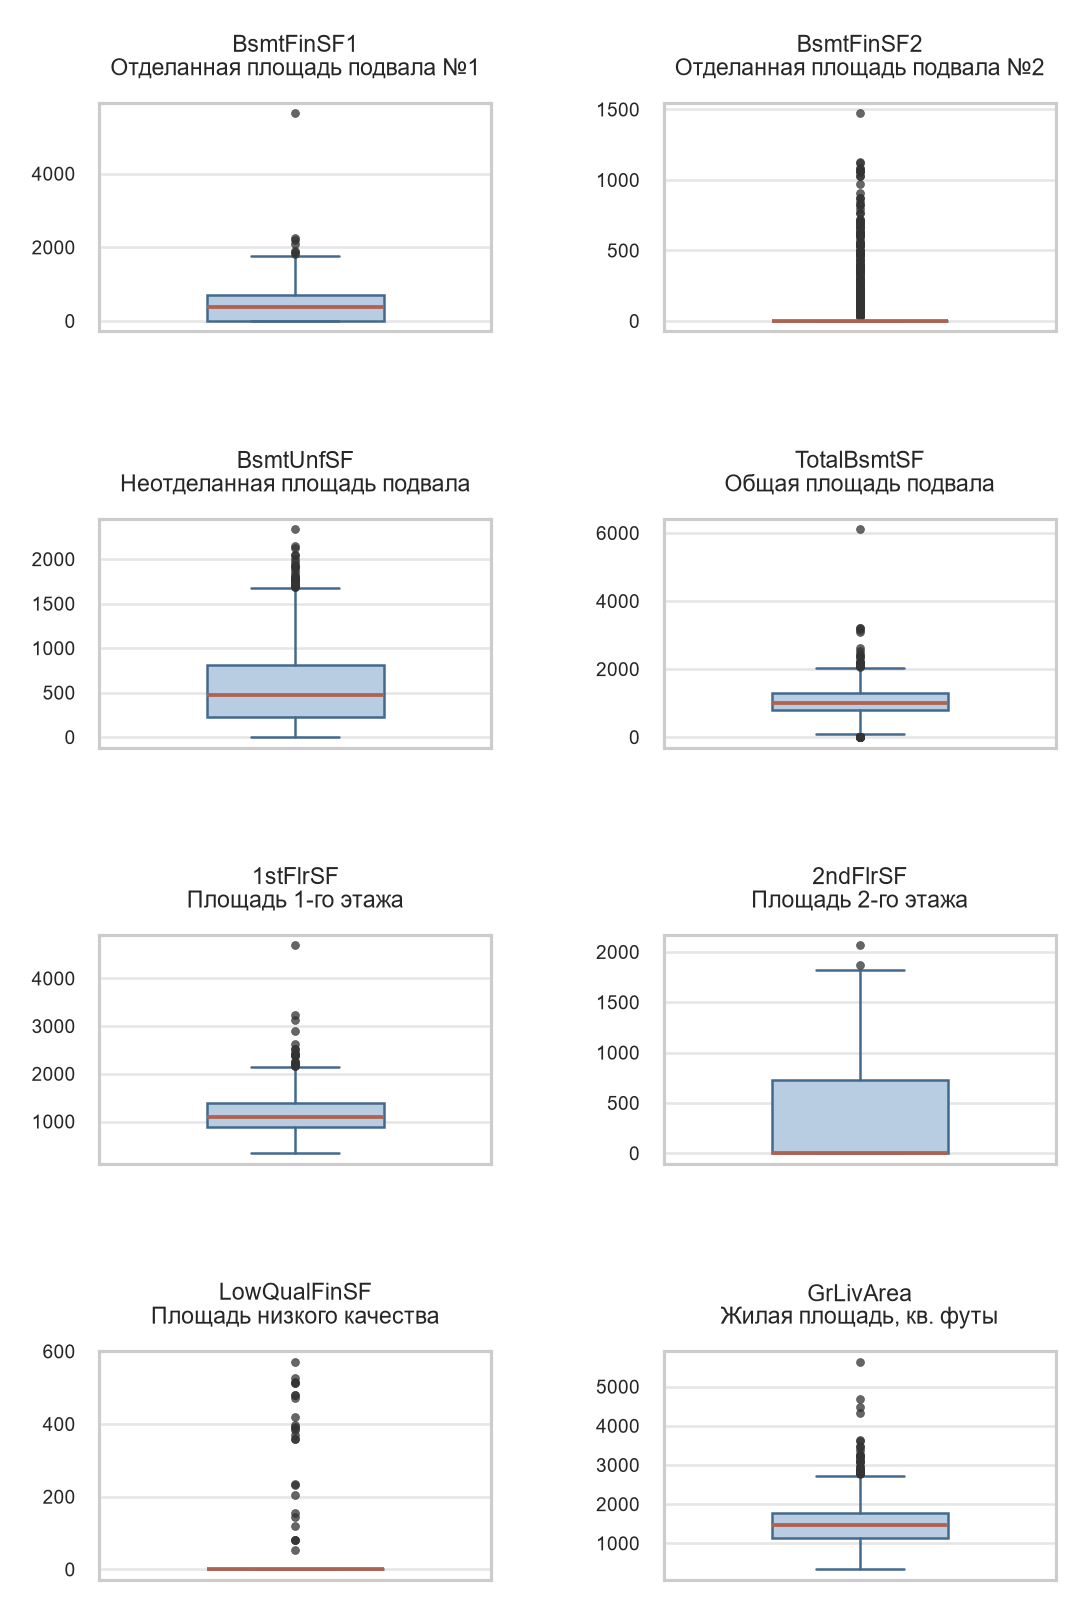

In [10]:
if "boxplots_02" in result.plots:
    display(Image(filename=str(result.plots["boxplots_02"])))

*Рисунок 1.7 — Выбросы в площадях подвала и жилых этажей.*

Большая площадь подвала, этажа или жилых помещений может быть естественной особенностью крупного дома. Например, при оценке `TotalBsmtSF` (общая площадь подвала) и `GrLivArea` (общая жилая площадь) важно сопоставлять необычные значения с ценой и площадями остальных помещений. Механическое удаление всех точек за пределами «усов» привело бы к потере редких, но потенциально достоверных объектов. При предобработке проверим такие записи по нескольким взаимосвязанным признакам.

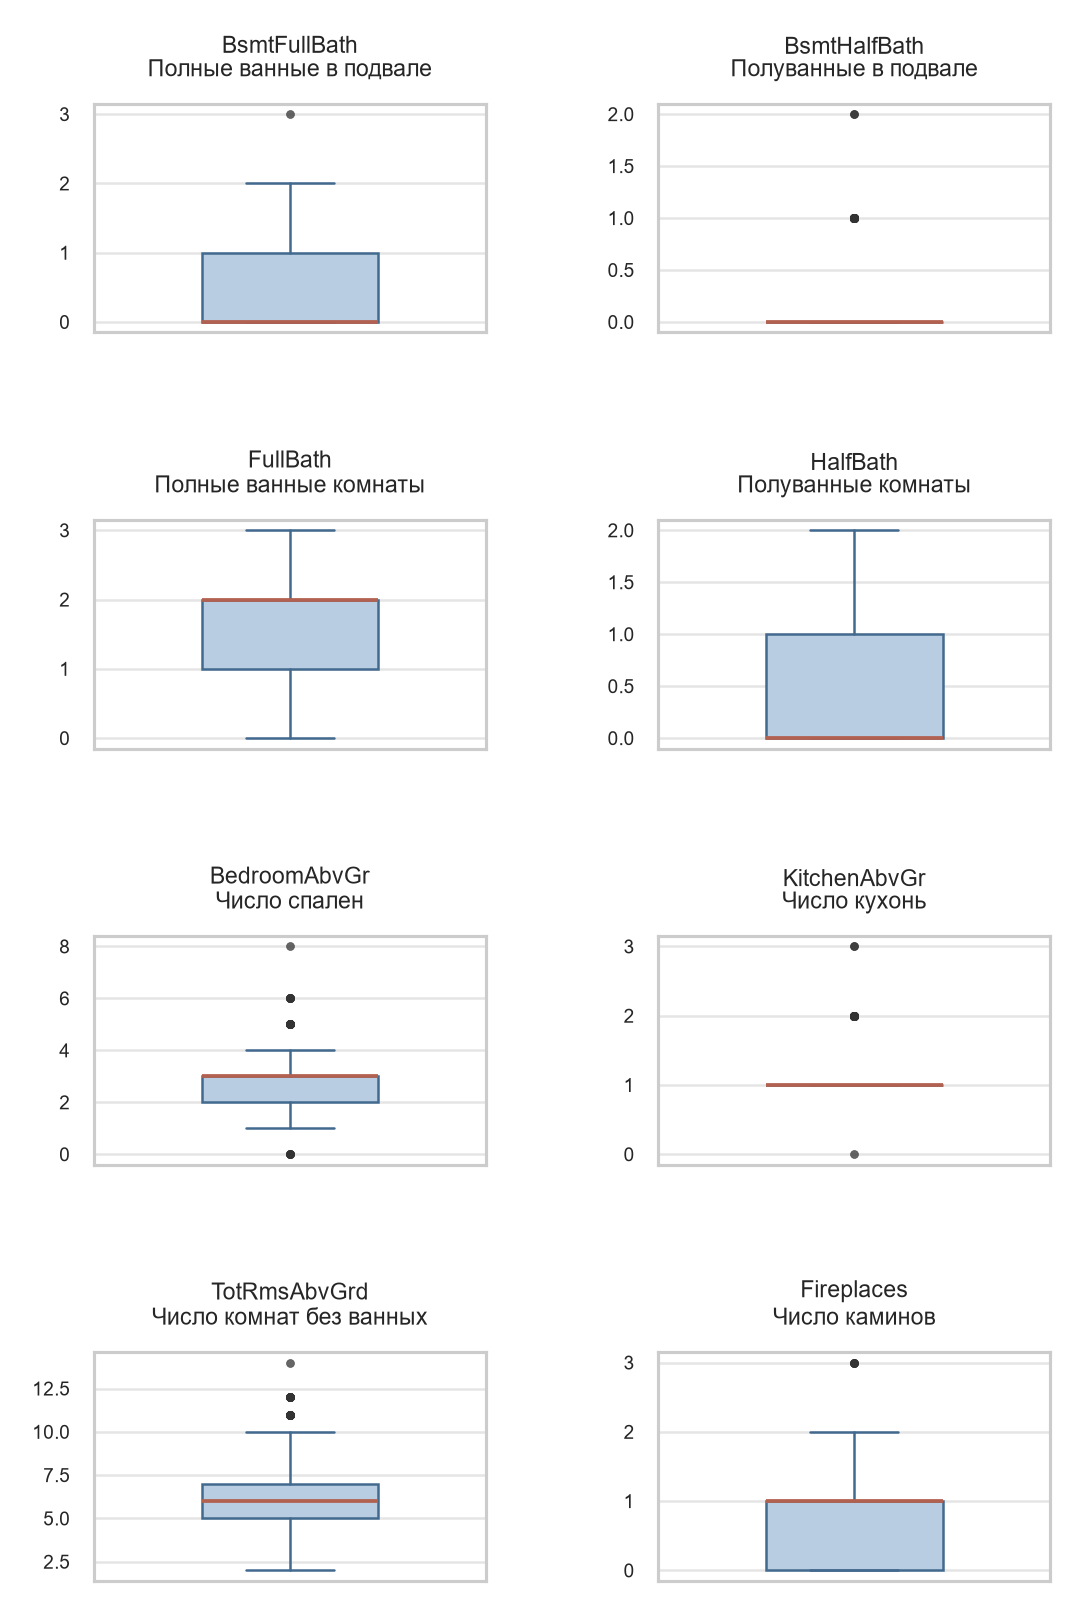

In [11]:
if "boxplots_03" in result.plots:
    display(Image(filename=str(result.plots["boxplots_03"])))

*Рисунок 1.8 — Распределение числа помещений и каминов.*

Число комнат, ванных и каминов измеряется целыми значениями. У `FullBath` (число полноценных ванных комнат), `BedroomAbvGr` (количество спален) и `Fireplaces` (количество каминов) редкие большие значения могут отображаться отдельными точками. Это ещё не означает, что сведения ошибочны. В дальнейшем необходимо проверять правдоподобие значений и их согласованность с характеристиками конкретного дома, а не автоматически отсекать всё необычное.

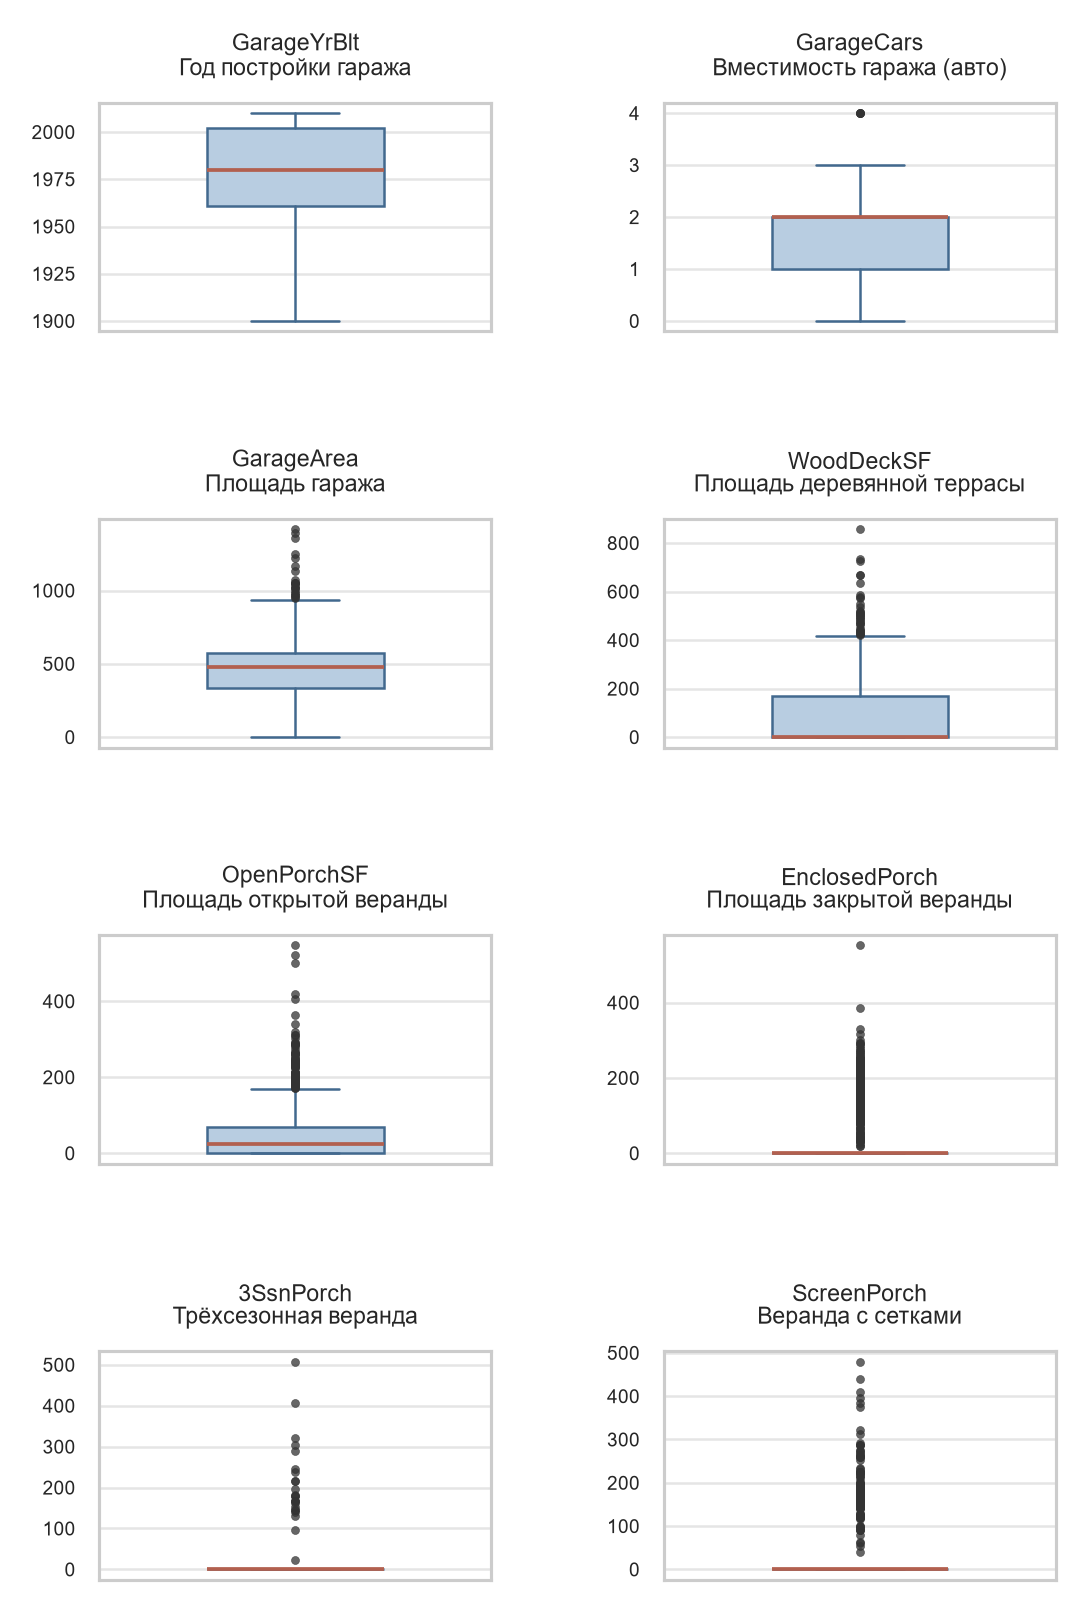

In [12]:
if "boxplots_04" in result.plots:
    display(Image(filename=str(result.plots["boxplots_04"])))

*Рисунок 1.9 — Необычные размеры гаража, террас и крыльца.*

В распределениях площадей гаража, террасы и крыльца часто встречаются нули и отдельные крупные значения. Например, у `GarageArea` (площадь гаража) редкие большие объекты могут быть реальными, а `WoodDeckSF` (площадь деревянной террасы) у домов без террасы закономерно равен нулю. При обработке данных сравним `GarageArea` (площадь гаража) с `GarageCars` (вместимость гаража), чтобы найти возможные несоответствия.

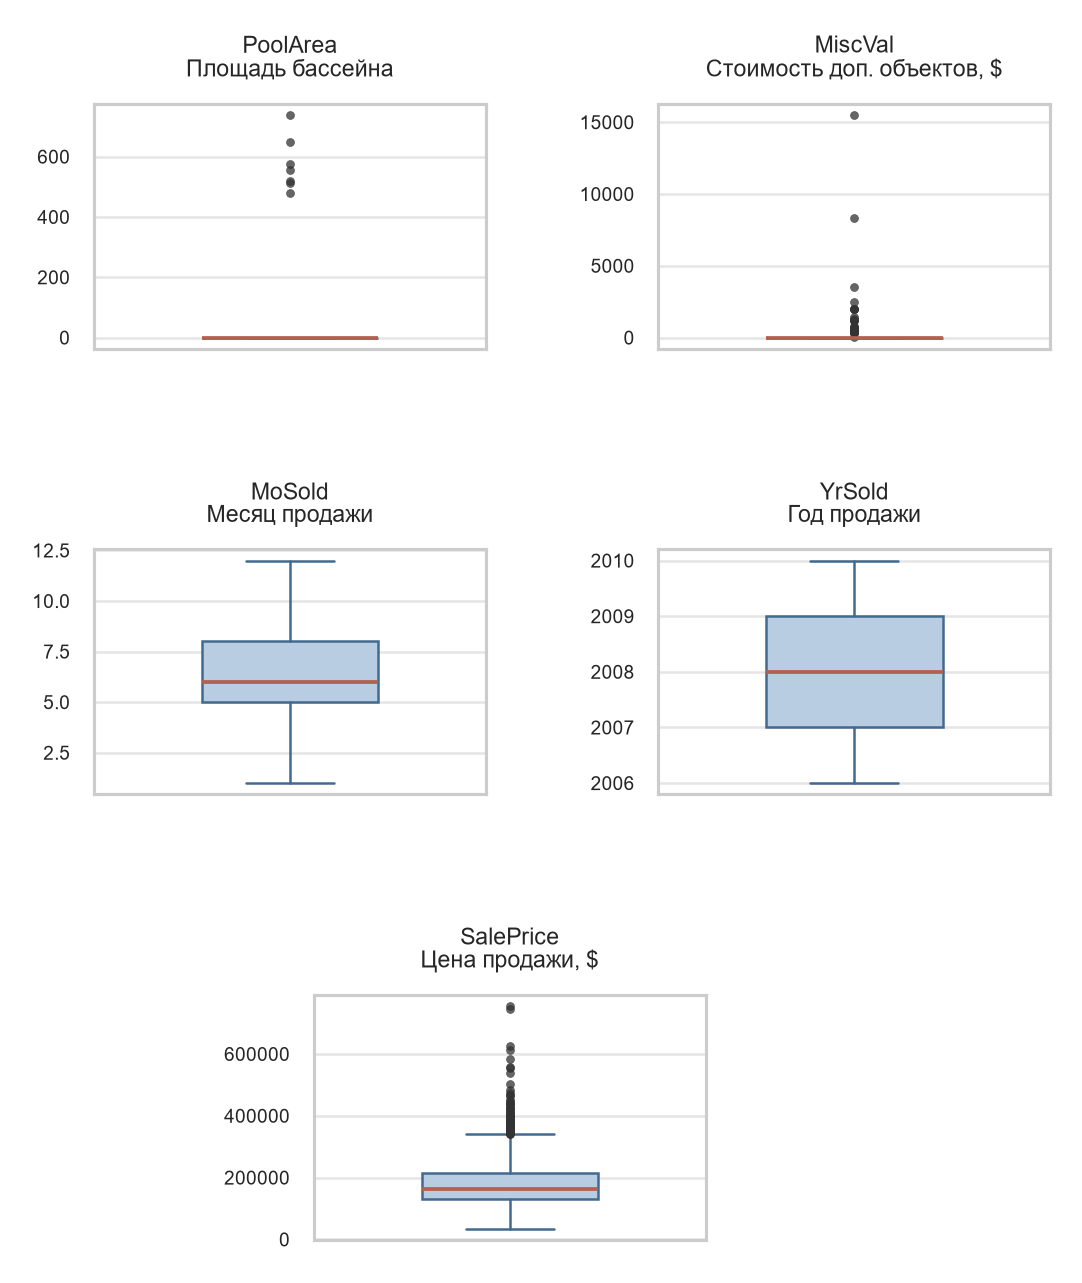

In [13]:
if "boxplots_05" in result.plots:
    display(Image(filename=str(result.plots["boxplots_05"])))

*Рисунок 1.10 — Цена продажи и редкие дополнительные объекты.*

Для `SalePrice` (цена продажи) видны отдельные дорогие дома за пределами верхнего «уса». Это потенциальные статистические выбросы, но не обязательно ошибки исходных данных. У `PoolArea` (площадь бассейна) и `MiscVal` (стоимость дополнительных объектов) межквартильный размах может оказаться равным нулю из-за большого количества нулей. При построении и сравнении моделей учтём дорогие объекты и отдельно проверим, насколько хорошо алгоритмы предсказывают их стоимость.

### Распределение цены продажи

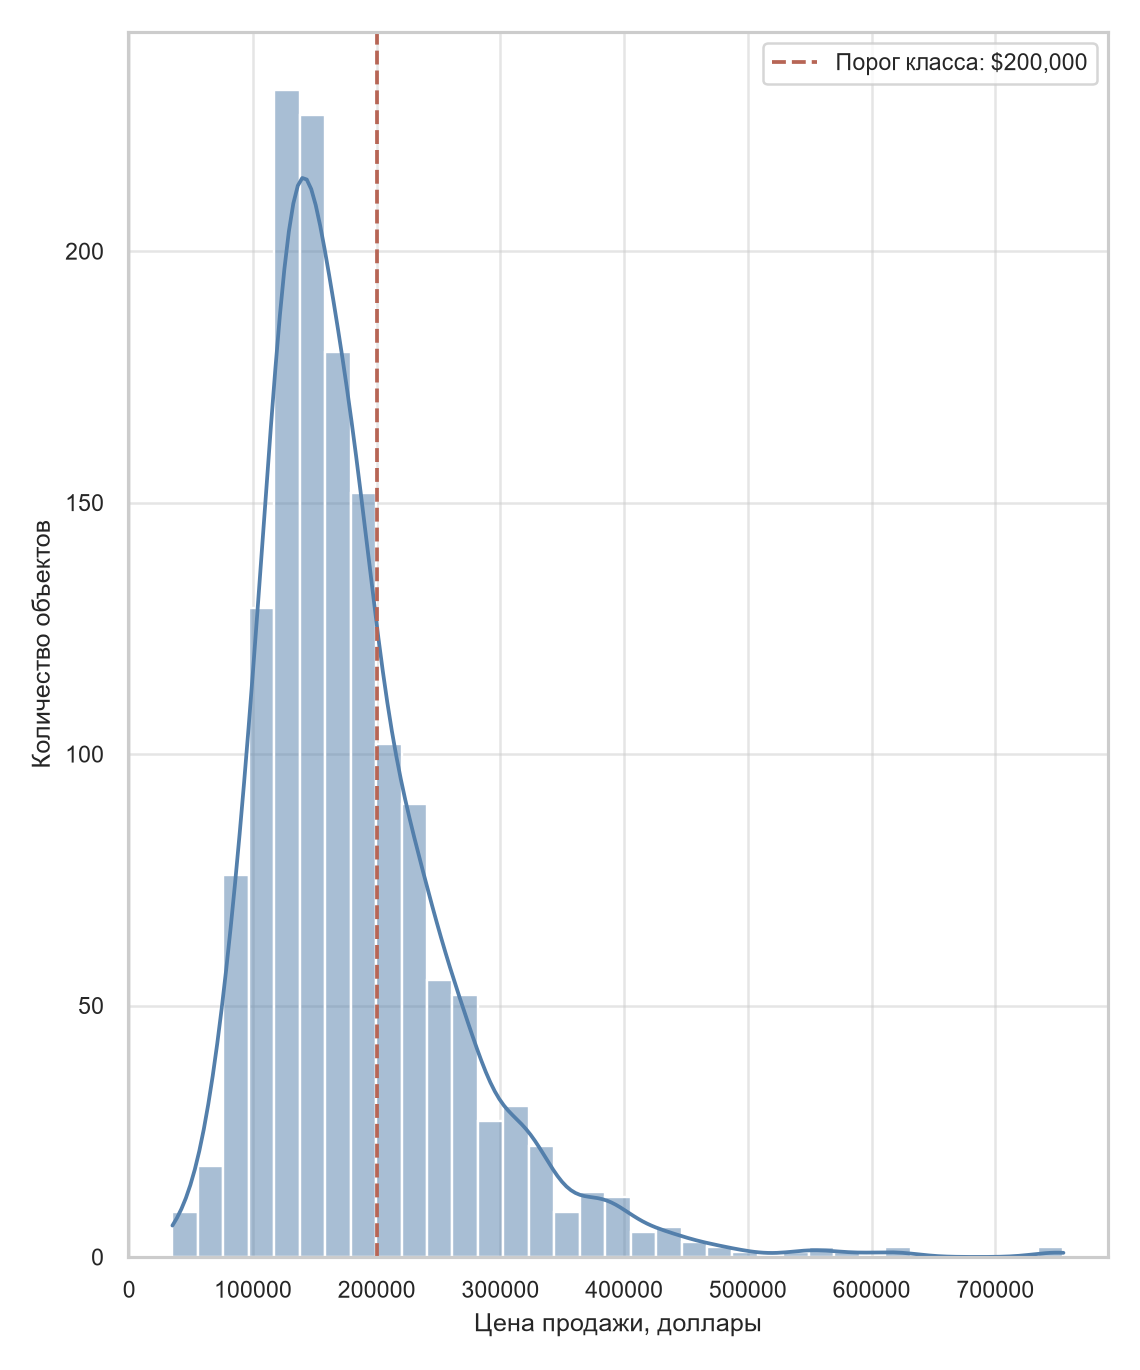

In [14]:
display(Image(filename=str(result.plots["target"])))

*Рисунок 1.11 — Распределение фактической стоимости продажи домов.*

Медианная цена ниже средней, а у гистограммы `SalePrice` (цена продажи) заметен длинный правый хвост: дорогих домов сравнительно немного. Вертикальная линия обозначает предварительный порог $200 000, по которому мы делим дома на две ценовые категории для задачи классификации. Этот порог потребуется оценить с точки зрения баланса классов. Для регрессионных моделей важно проверить качество прогнозов на дорогих объектах, чтобы они не оставались без внимания за хорошими средними метриками.

## Корреляционный анализ и парные зависимости

Сопоставляем линейную связь числовых характеристик с ценой и ищем группы взаимосвязанных признаков. Корреляция не доказывает причинность.

Наиболее сильные корреляции с SalePrice:


,r (Пирсон)
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


Пары с |r| ≥ 0.8 (потенциальная мультиколлинеарность):


,Признак A,Признак B,Корреляция r
0,GarageCars,GarageArea,0.882475
1,YearBuilt,GarageYrBlt,0.825667
2,GrLivArea,TotRmsAbvGrd,0.825489
3,TotalBsmtSF,1stFlrSF,0.819530


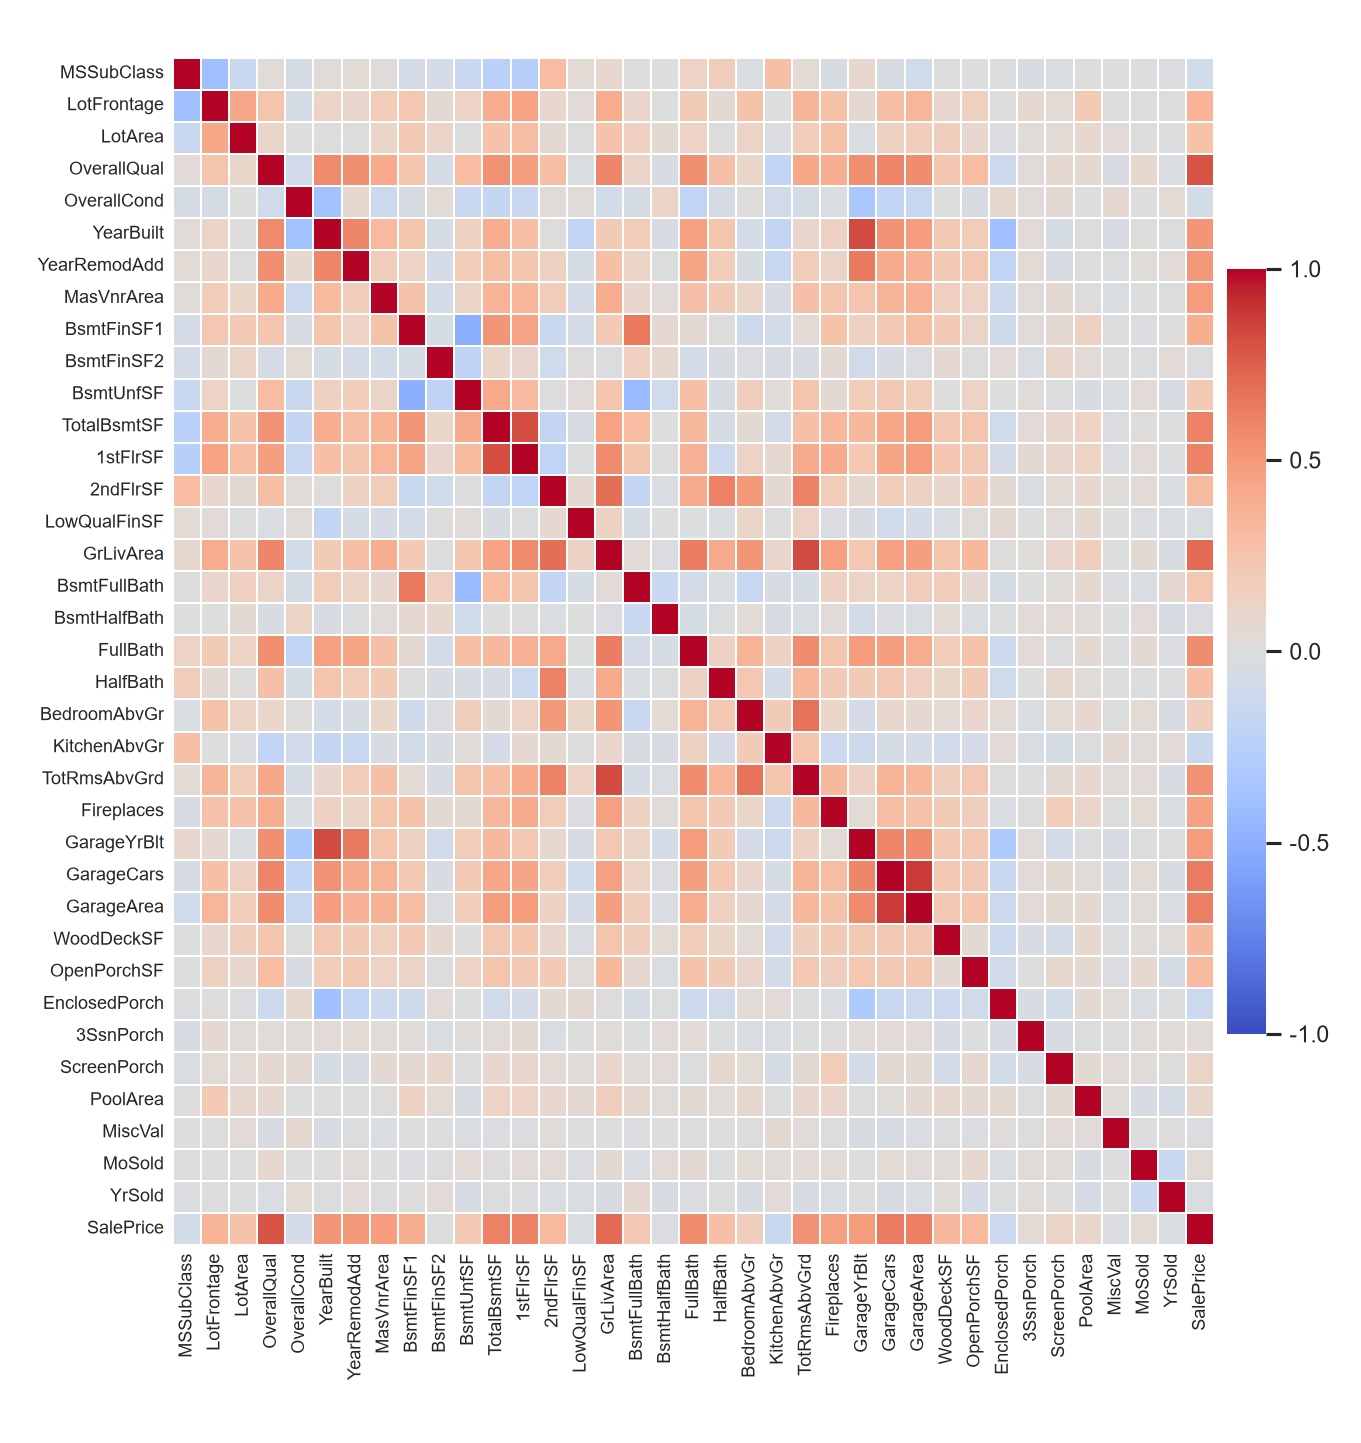

In [15]:
print("Наиболее сильные корреляции с SalePrice:")
display(result.correlations.head(15).to_frame("r (Пирсон)"))
print("Пары с |r| ≥ 0.8 (потенциальная мультиколлинеарность):")
display(result.correlated_pairs)
display(Image(filename=str(result.plots["correlations"])))

*Рисунок 1.12 — Корреляционная матрица числовых признаков и цены продажи.*

Красные оттенки на матрице показывают положительную линейную связь между признаками, синие — отрицательную, а светлые — близкую к нулю. Наиболее заметная связь с `SalePrice` (ценой продажи) наблюдается у `OverallQual` (общего качества дома), `GrLivArea` (жилой площади), `GarageCars` (вместимости гаража в автомобилях), `GarageArea` (площади гаража) и `TotalBsmtSF` (общей площади подвала). Между некоторыми характеристиками также есть сильные связи, например между площадью гаража и его вместимостью. Это может означать, что несколько признаков частично повторяют одну и ту же информацию. При предобработке данных необходимо проверить такую взаимосвязь (мультиколлинеарность) и её влияние на качество моделей. Точные коэффициенты приведены в таблице выше.

### Парные зависимости ключевых характеристик

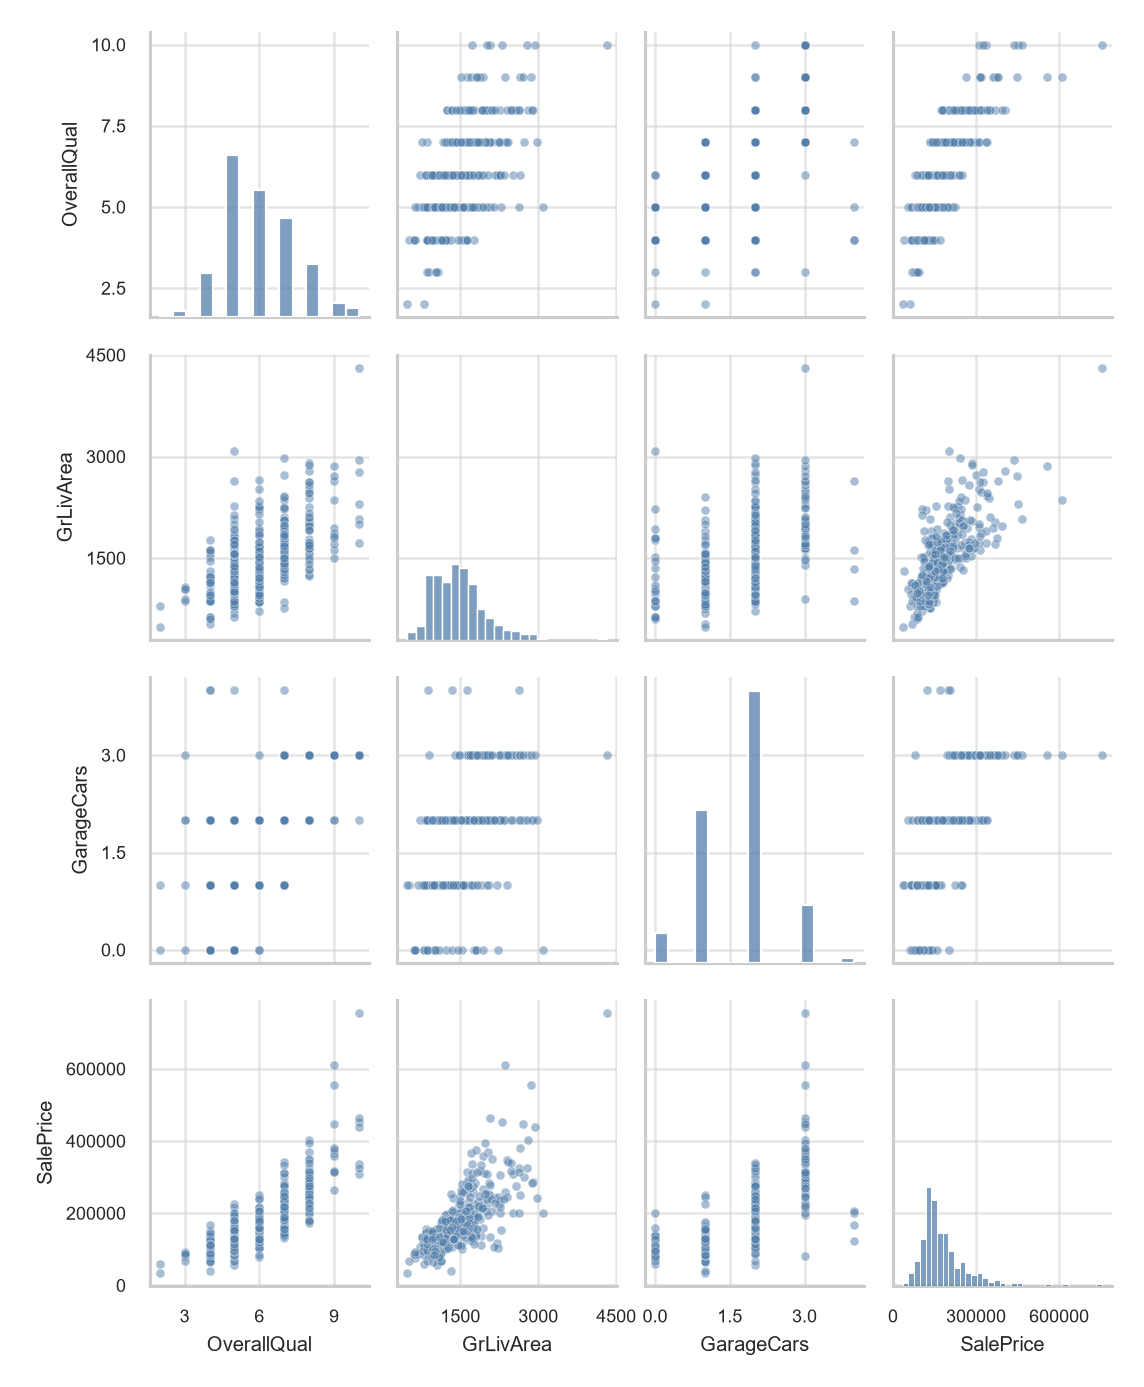

In [16]:
if "pairplot_01" in result.plots:
    display(Image(filename=str(result.plots["pairplot_01"])))

*Рисунок 1.13 — Парные зависимости наиболее связанных с ценой признаков (часть 1).*

На диагонали показаны распределения отдельных признаков, а в остальных ячейках — взаимосвязи между ними. С ростом `OverallQual` (общего качества дома) и `GrLivArea` (жилой площади) стоимость продажи, как правило, увеличивается, хотя встречаются дома со схожими характеристиками и разными ценами. `GarageCars` (вместимость гаража в автомобилях) принимает только целые значения, поэтому точки на диаграммах образуют полосы. Для удобства чтения графики построены на одной и той же воспроизводимой случайной выборке до 400 объектов. Коэффициенты корреляции в таблице выше рассчитаны по полным доступным данным.

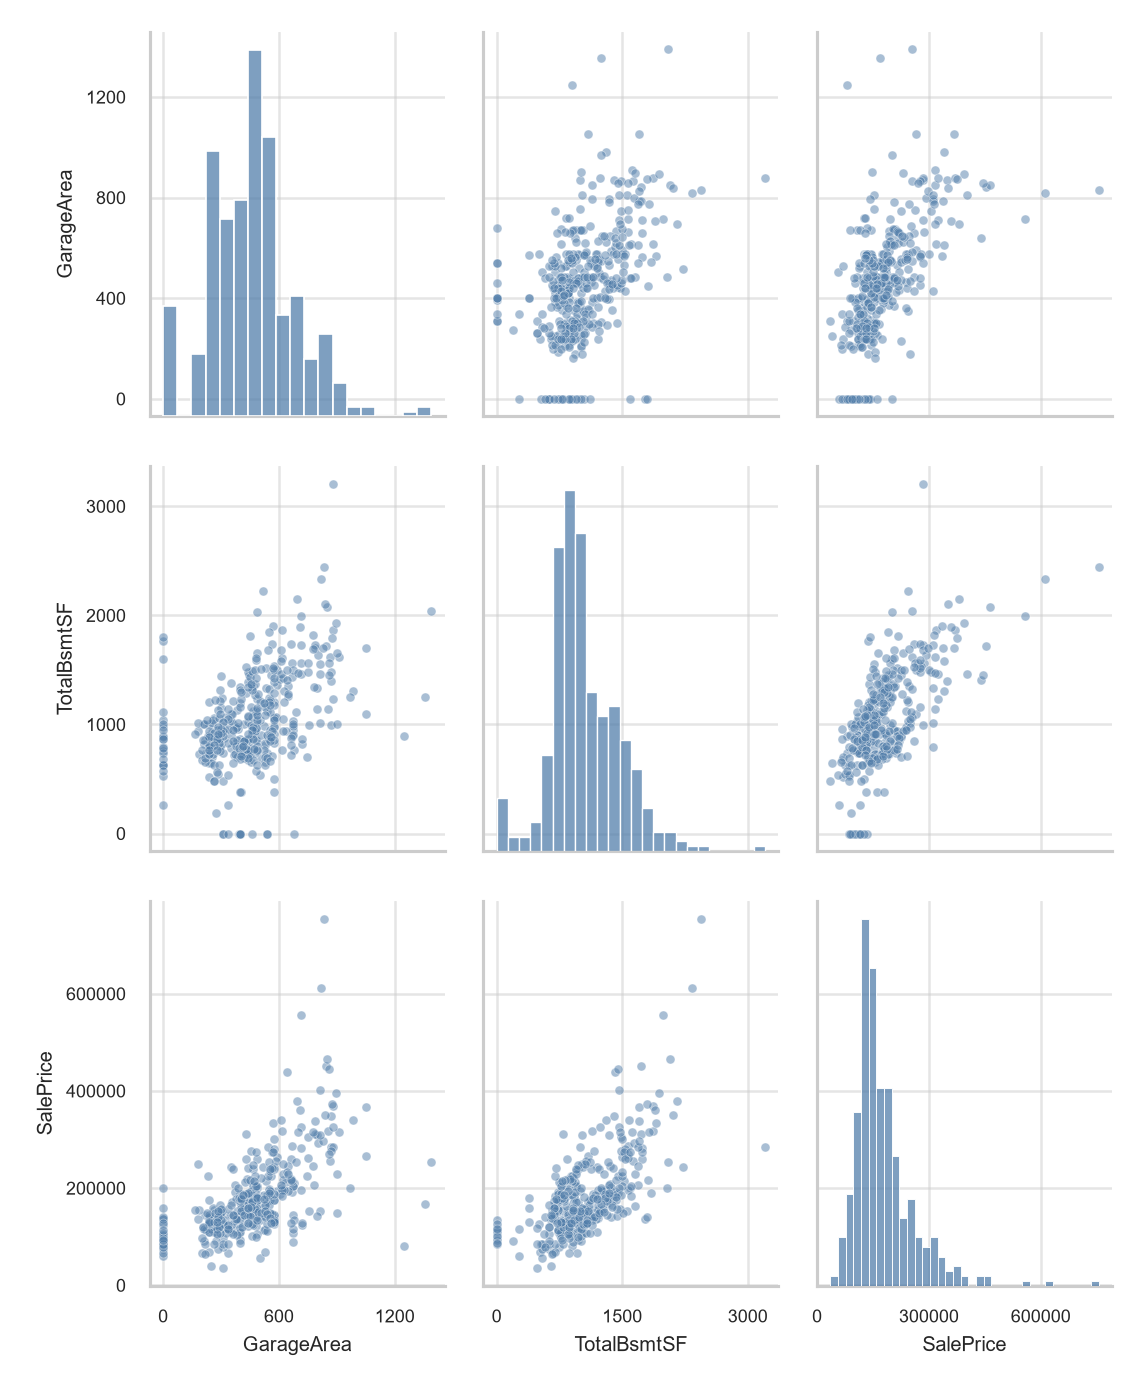

In [17]:
if "pairplot_02" in result.plots:
    display(Image(filename=str(result.plots["pairplot_02"])))

*Рисунок 1.14 — Парные зависимости связанных с ценой характеристик (часть 2).*

`GarageArea` (площадь гаража) и `TotalBsmtSF` (общая площадь подвала) обычно положительно связаны с `SalePrice` (ценой продажи). Однако у домов с одинаковой площадью гаража или подвала стоимость может существенно различаться: одной характеристики недостаточно для точного прогноза. В дальнейшем сравним модели по результатам на отдельных тестовых данных, которые не использовались при их обучении.

## Метод главных компонент — PCA

Ниже — двумерная проекция **числовых характеристик без `Id` и `SalePrice`**. Только для иллюстрации выполняются заполнение пропусков медианой и стандартизация. Это **не обучающий pipeline**, для моделей трансформации будут подбираться только на тренировочных данных.

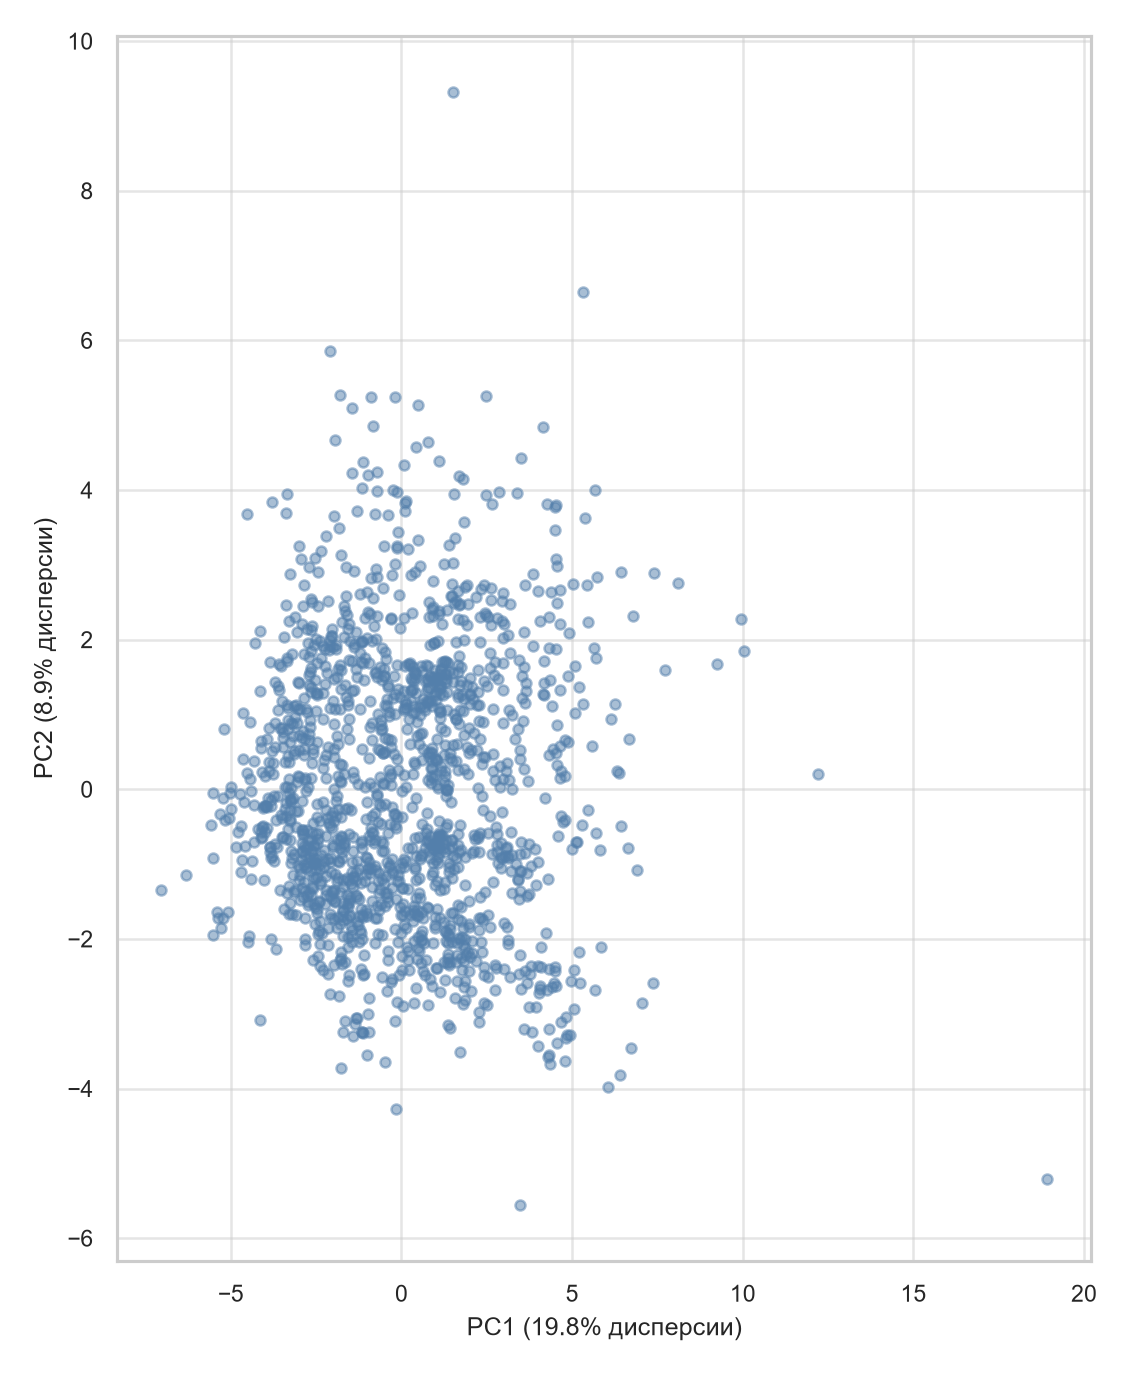

In [18]:
if "pca" in result.plots:
    display(Image(filename=str(result.plots["pca"])))

*Рисунок 1.15 — Двумерная проекция числовых характеристик методом главных компонент (PCA).*

В двумерной проекции PCA (метода главных компонент) большинство домов образуют общее облако, а отдельные точки находятся в стороне. Доли информации о разбросе объектов, сохранённые двумя первыми компонентами, указаны на осях. По этой проекции нельзя уверенно утверждать ни наличие, ни отсутствие групп похожих домов. Дальнейшая кластеризация будет учитывать больше характеристик.

## Постановка задач машинного обучения

**Регрессия** — предсказать реальную цену продажи `SalePrice` (USD). Метрики: MAE, RMSE, R².

**Классификация** — определить, дорогой ли дом относительно предварительного фиксированного порога **$200 000**. Метрики — Precision, Recall, F1, ROC-AUC. Сам `SalePrice` и любые признаки, выведенные из него, исключаются из входов модели. Окончательный порог обоснуем по балансу классов.

**Кластеризация** — выделить группы похожих домов без использования `SalePrice`, категории цены и `Id`, метод K-means, визуализация PCA/t-SNE.


In [19]:
print(f"Предварительная граница категории: ${HIGH_PRICE_THRESHOLD:,}")
display(result.class_balance)

Предварительная граница категории: $200,000


,Класс,Количество,"Доля, %"
0,"0 — менее $200,000",1025,70.2
1,"1 — от $200,000",435,29.8


## Итоговые выводы по EDA

Исследование показало, что данные о недвижимости неоднородны. Часть характеристик записана категориальными кодами, часть представляет площади и количества, а некоторые признаки часто равны нулю. Пропуски тоже имеют разный смысл, иногда информации не хватает, а иногда соответствующий объект просто отсутствует. При подготовке данных необходимо учитывать эти различия, а при сравнении моделей проверять влияние дорогих и нетипичных домов, а также сильно взаимосвязанных признаков. `SalePrice` (цена продажи) не должна попадать во входные данные классификации и кластеризации, а `Id` (идентификатор записи) не является характеристикой дома.

Следующим этапом подготовим воспроизводимую последовательность преобразований, применяемую без утечки информации из тестовой выборки. Сводный отчёт сохраняется в `outputs/eda/lr01_eda_summary.md`, исходный файл Kaggle остаётся без изменений.

In [20]:
print("Лабораторная работа №1 завершена.")
print(f"Сводный отчёт: {result.report_path}")
print(f"Количество подготовленных рисунков: {len(result.plots)}")

Лабораторная работа №1 завершена.
Сводный отчёт: F:\JetBrainsProjects\PycharmProjects\house-prices-ai\outputs\eda\lr01_eda_summary.md
Количество подготовленных рисунков: 15
